# Analysis of antibody optimizations and simulations with designed antibodies
## Generates Fig. S5, Fig. S6, Fig. S7

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import os
import glob
import re
import seaborn as sns

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "legend.fontsize": 'small',
    "figure.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

params = {
    "lambda_T": 1e7,
    "d": 0.2,

    #Infection dynamics
    "beta_wt": 2e-9,
    "gamma": 1.0,
    "delta1": 0.5,
    "delta2": 1.0,
    "n": 1000.0,
    "c": 20.0,

    #Binding affinity
    "RT": 0.616,
    "KD_WT": 1e-8,
    "h": 0.1,
    "K": 5,

    #Antibody dynamics
    "k": 0.664,
    "a1": 0.288,
    "a2": 0.070
}

## Generate Fig. S5: optimization traces and runs of one-step/global optima

In [2]:
def format_dose(dose):
    return f"{dose:.1e}".replace(".", "p")

def plot_viral_load_panel(ax, dose, decay_mode,
    base_dir='../Simulation_data/WT_Ab/',
    timepoints=(90, 180, 365, 540, 730), seeds=[i for i in range(1, 11)], show_legend=False, legend_kwargs=None,
    ylimits=(1e-1, 3e5), xlimits=(0, 900), linewidth=2.4, shade_alpha=0.22, mode="shade", seed_alpha=0.65):
    
    if isinstance(timepoints, (int, float)):
        timepoints = [timepoints]
    if legend_kwargs is None:
        legend_kwargs = dict(loc="upper right", fontsize="small", frameon=False)
    
    palette = sns.husl_palette(len(timepoints), h=0.55, l=0.5)
    sim_dir = os.path.join(base_dir, f"sim_outputs_{decay_mode}")
    legend_handles = []
    legend_labels = []
    for i, tp in enumerate(timepoints):
        seed_series = []
        seed_times_list = []
        for seed in seeds:
            fname = os.path.join(sim_dir, f"totals_time{tp}_dose{format_dose(dose)}_seed{seed}.csv")
            df = pd.read_csv(fname)
            t = df['time'].to_numpy(dtype=float)
            v = df['sum_V'].to_numpy(dtype=float)
            
            #Zero out viral load if it drops below 1 virus particle
            extinct = np.where(v < 1)[0]
            if extinct.size > 0:
                v[extinct[0]:] = 0.0
            seed_times_list.append(t)
            seed_series.append(v)
        common_times = np.unique(np.concatenate(seed_times_list))
        common_times.sort()
        n_seeds_present = len(seed_series)
        values_on_grid = np.full((n_seeds_present, common_times.size), np.nan, dtype=float)
        for si, (t, v) in enumerate(zip(seed_times_list, seed_series)):
            tmin, tmax = t.min(), t.max()
            mask = (common_times >= tmin) & (common_times <= tmax)
            if mask.any():
                values_on_grid[si, mask] = np.interp(common_times[mask], t, v)
        with np.errstate(invalid="ignore"):
            mean_vals = np.nanmean(values_on_grid, axis=0)
            min_vals = np.nanmin(values_on_grid, axis=0)
            max_vals = np.nanmax(values_on_grid, axis=0)
        if mode == 'shade':
            ax.fill_between(common_times, min_vals/5000, max_vals/5000, color=palette[i], alpha=shade_alpha, linewidth=0)
            ax.plot(common_times, mean_vals/5000, color=palette[i], linewidth=linewidth, label=f"t={tp}", solid_capstyle='round')
        else:
            for si in range(n_seeds_present):
                row = values_on_grid[si]
                ax.plot(common_times, row/5000, color=palette[i], linewidth=linewidth*0.85, alpha=seed_alpha, solid_capstyle='round', zorder=1)
        legend_handles.append(None)
        legend_labels.append(f"t = {tp}")
    ax.set_yscale("log")
    ax.set_ylim(ylimits)
    ax.set_xlim(xlimits)
    ax.set_xlabel("Time (d)")
    ax.set_ylabel("Viral Load (mL$^{-1}$)")
    if show_legend:
        leg = ax.legend(**legend_kwargs)
    
    return ax

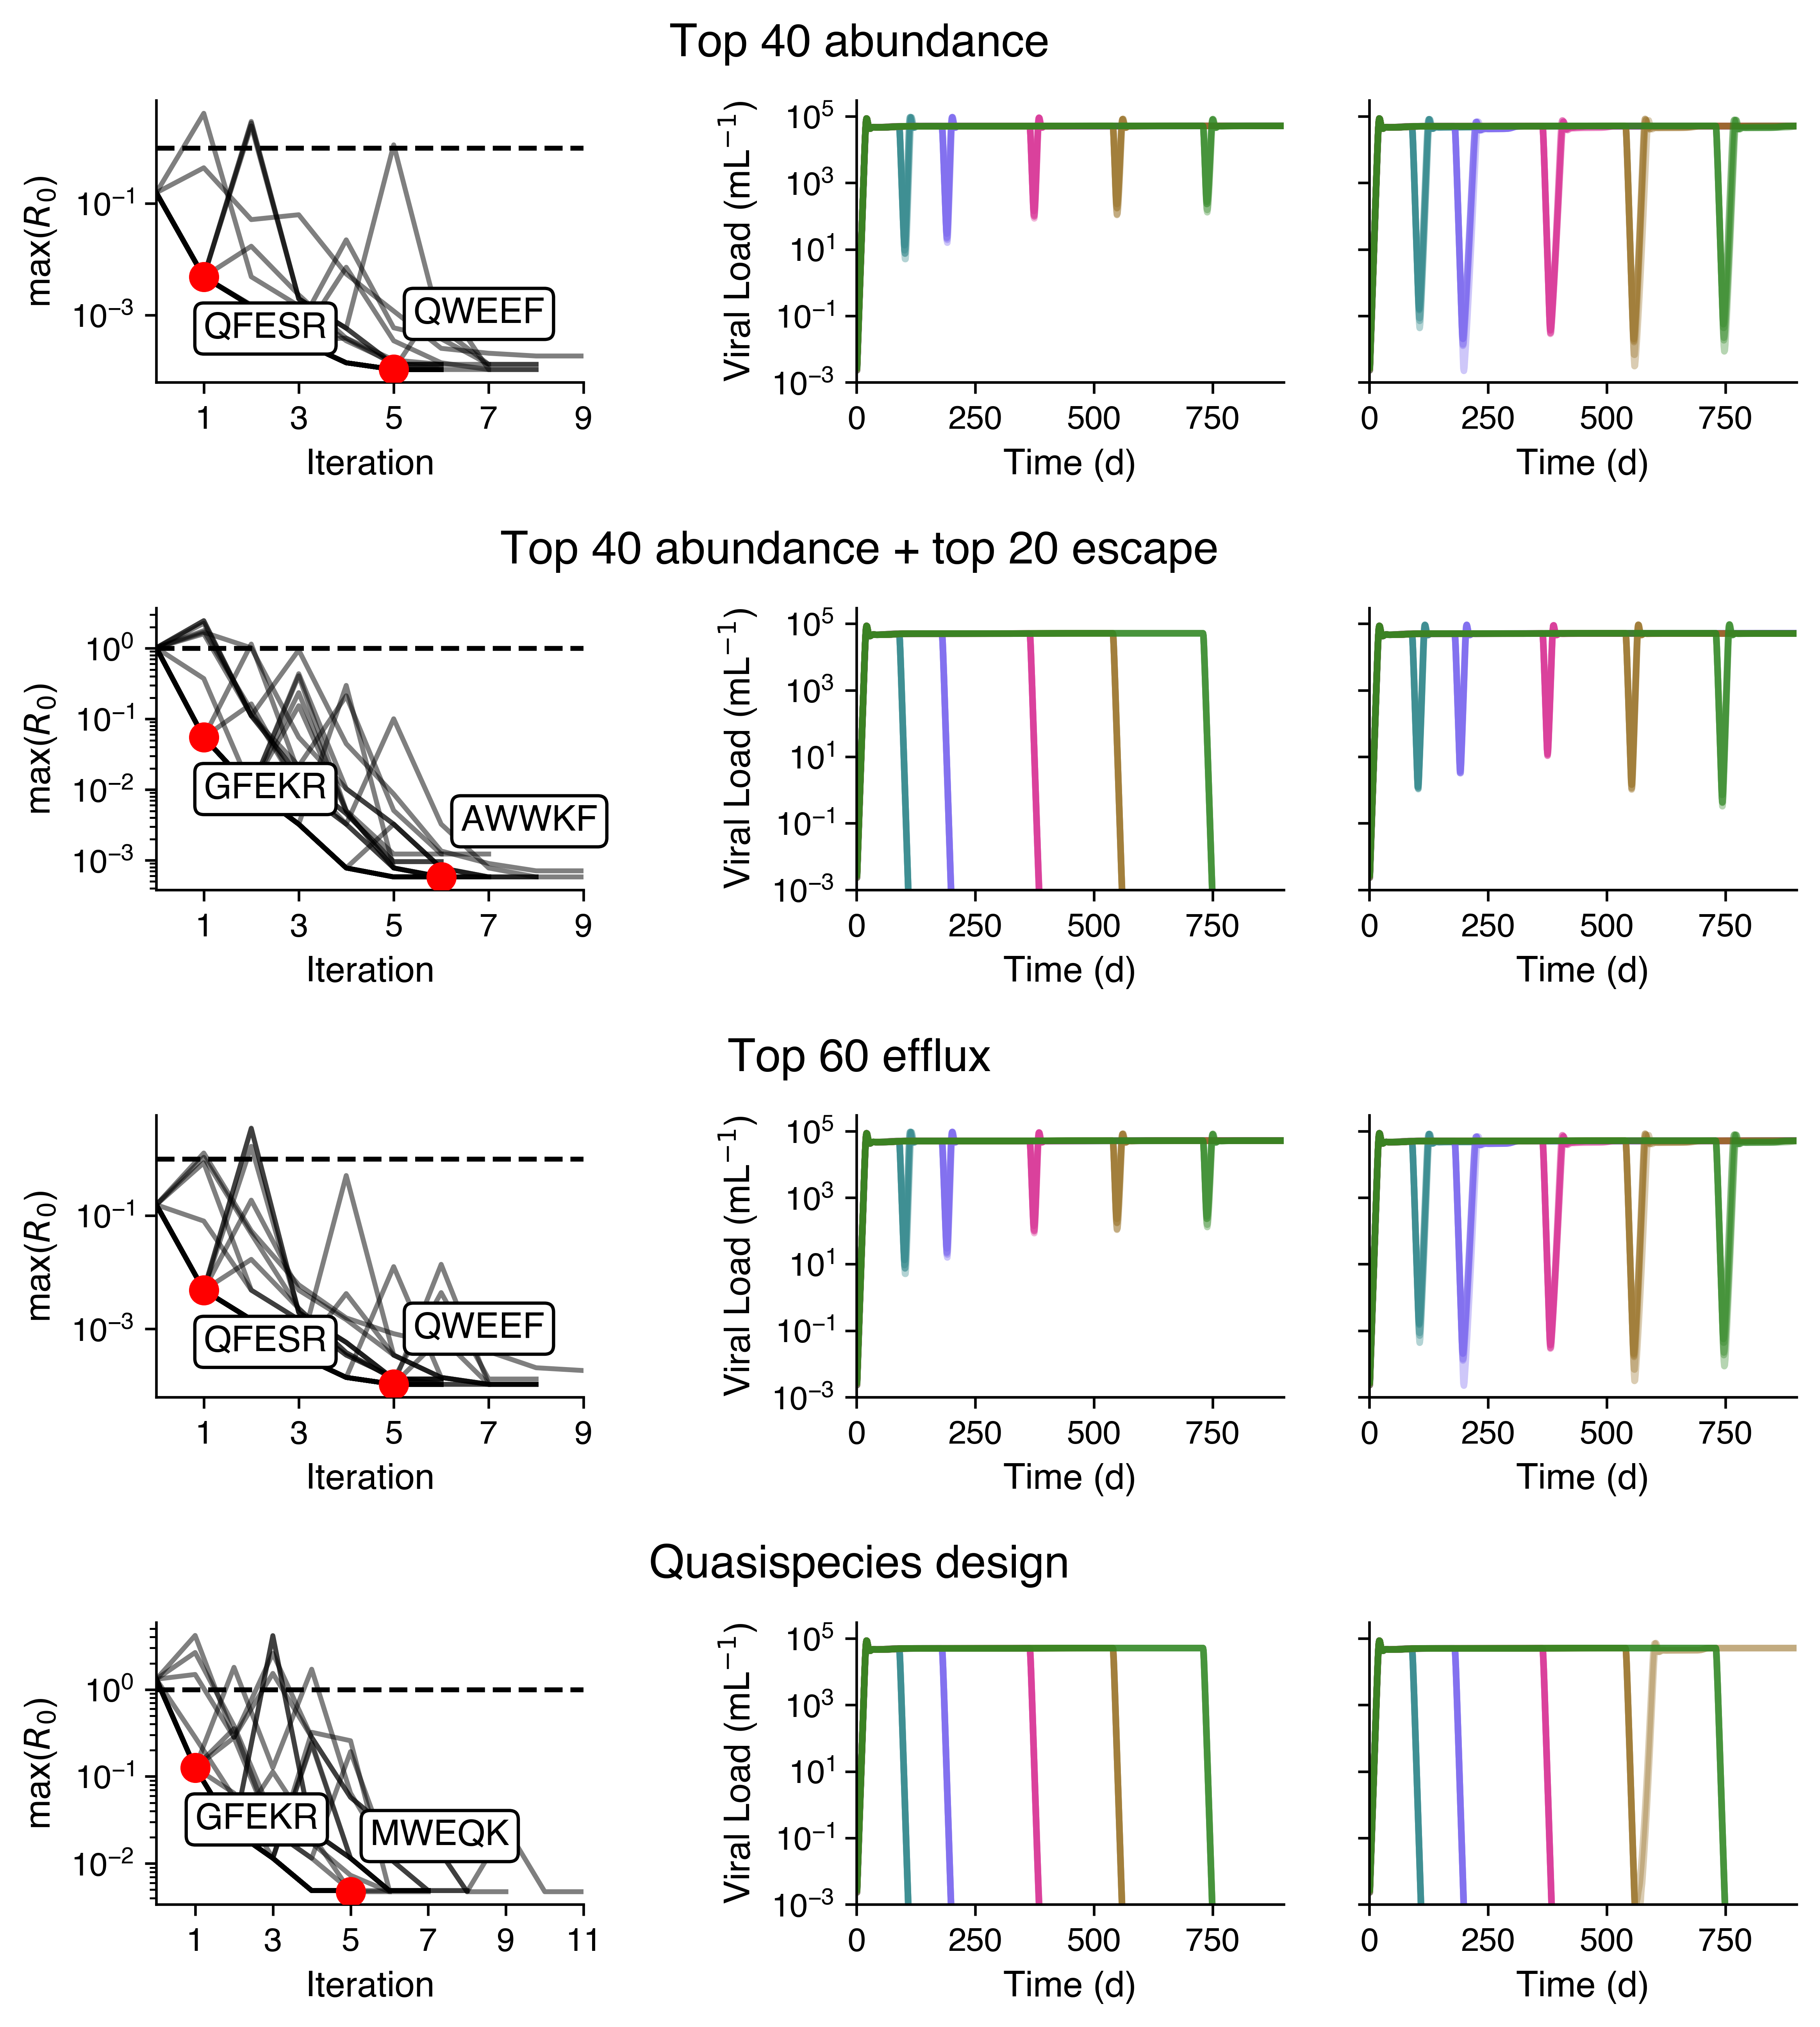

In [3]:
def plot_max_r0_traces(base_dir, ax=None, trace_filename="optimization_trace.csv",  title=None):
    seed_dirs = []
    for path in glob.glob(os.path.join(base_dir, "seed_*")):
        m = re.match(r"seed_(\d+)$", os.path.basename(path))
        seed_dirs.append((int(m.group(1)), path))
    seed_dirs = sorted(seed_dirs, key=lambda x: x[0])

    def _annotate_point(ax, row, offset):
        ax.scatter(row["iteration"], row["max_r0"], s=60, color='r', linewidths=1.5, zorder=5)
        ax.annotate(row["selected_ab_label"][3:], xy=(row["iteration"],row["max_r0"]), xytext=offset, textcoords="offset points", fontsize=11, color='k', fontweight="bold", ha="left", va="bottom", zorder=6, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor='k', linewidth=1.0))
    
    seed_data = {}
    combined_rows = []
    for i, (seed_idx, seed_path) in enumerate(seed_dirs):
        df = pd.read_csv(os.path.join(seed_path, trace_filename))
        ax.plot(df["iteration"], df["max_r0"], color='k', alpha=0.5)
        seed_data[seed_idx] = df
        combined_rows.append(df.assign(_seed=seed_idx))

    combined = pd.concat(combined_rows, ignore_index=True)
    iter1_df = combined[combined["iteration"] == 1]
    step1_opt = iter1_df.loc[iter1_df["max_r0"].idxmin()]
    global_opt = combined.loc[combined["max_r0"].idxmin()]
    _annotate_point(ax, step1_opt, offset=(0, -21))
    _annotate_point(ax, global_opt, offset=(6, 12))

    ax.axhline(1, linestyle='--', color='k')
    ax.set_xlabel("Iteration")
    ax.set_yscale('log')
    ax.set_ylabel(r"max($R_0$)")
    ax.set_title(title)

base_dir_optimizations = '../Simulation_data/Optimization_traces'

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(8, 10))
axes = axes.flatten()
fig.subplots_adjust(hspace=0.8)

for i in range(4):
    pos2 = axes[3*i + 1].get_position()
    pos3 = axes[3*i + 2].get_position()
    shift = 0.1
    axes[3*i + 1].set_position([pos2.x0 + shift, pos2.y0, pos2.width, pos2.height])
    axes[3*i + 2].set_position([pos3.x0 + shift, pos3.y0, pos3.width, pos3.height])


row_labels = ["Top 40 abundance", "Top 40 abundance + top 20 escape", "Top 60 efflux", "Quasispecies design"]
for i in range(4):
    y = axes[i*3].get_position().y1
    fig.text(0.5, y + 0.015, row_labels[i], ha="center", va="bottom", fontsize=14, fontweight="bold")

#Top 40 abundance
plot_max_r0_traces(os.path.join(base_dir_optimizations, 'Top40_Abundance'), ax=axes[0])
plot_viral_load_panel(axes[1], 2.8e-6, 'biphasic', base_dir='../Simulation_data/QFESR_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
plot_viral_load_panel(axes[2], 2.8e-6, 'biphasic', base_dir='../Simulation_data/QWEEF_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
axes[0].set_xlim([0,9])
axes[0].set_xticks([1, 3, 5, 7, 9])
axes[2].set_ylabel("")
axes[2].set_yticklabels("")

#Top 40 abundance + top 20 escape
plot_max_r0_traces(os.path.join(base_dir_optimizations, 'Top40_Abundance_Top20_Escape'), ax=axes[3])
plot_viral_load_panel(axes[4], 2.8e-6, 'biphasic', base_dir='../Simulation_data/GFEKR_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
plot_viral_load_panel(axes[5], 2.8e-6, 'biphasic', base_dir='../Simulation_data/AWWKF_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
axes[3].set_xlim([0,9])
axes[3].set_xticks([1, 3, 5, 7, 9])
axes[5].set_ylabel("")
axes[5].set_yticklabels("")

#Top 60 efflux
plot_max_r0_traces(os.path.join(base_dir_optimizations, 'Top60_Efflux'), ax=axes[6])
plot_viral_load_panel(axes[7], 2.8e-6, 'biphasic', base_dir='../Simulation_data/QFESR_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
plot_viral_load_panel(axes[8], 2.8e-6, 'biphasic', base_dir='../Simulation_data/QWEEF_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
axes[6].set_xlim([0,9])
axes[6].set_xticks([1, 3, 5, 7, 9])
axes[8].set_ylabel("")
axes[8].set_yticklabels("")

#Quasispecies design
plot_max_r0_traces(os.path.join(base_dir_optimizations, 'Quasispecies_design'), ax=axes[9])
plot_viral_load_panel(axes[10], 2.8e-6, 'biphasic', base_dir='../Simulation_data/GFEKR_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
plot_viral_load_panel(axes[11], 2.8e-6, 'biphasic', base_dir='../Simulation_data/MWEQK_Ab', seeds=range(1, 6), ylimits=(1e-3, 3e5), mode='seed', seed_alpha=0.35)
axes[9].set_xlim([0,11])
axes[9].set_xticks([1, 3, 5, 7, 9, 11])
axes[11].set_ylabel("")
axes[11].set_yticklabels("")

plt.savefig('FigS5', bbox_inches='tight')

## Generate Fig. S6: ddG landscapes for antibody optimizations

In [4]:
def get_topk_at_time(topk_df, time_value, top_k=20):
    times = topk_df["time"].unique()
    nearest = times[np.argmin(np.abs(times - time_value))]
    snap = topk_df[topk_df["time"] == nearest]
    agg = snap.groupby("sequence", as_index=False)["V"].sum()
    agg = agg.sort_values("V", ascending=False)
    return list(agg["sequence"].head(top_k))

def hamming_dist(a, b):
    return sum(x != y for x, y in zip(a, b))

def min_hamming_to_set(seq, target_seqs):
    """Minimum Hamming distance from seq to any sequence in target_seqs."""
    if not target_seqs:
        return None
    return min(hamming_dist(seq, t) for t in target_seqs)

def get_escape_seqs(df, params, dose, ddg_col='ddG', ddg_ab_col='ddG_Ab', ddg_threshold=1):
    """Return the set of sequences with R0 > threshold at given antibody dose."""
    xs = df[ddg_col].values
    ys = df[ddg_ab_col].values
    r0_vals = np.asarray(r0_fun(xs, ys, dose, params), dtype=float)
    return set(df.loc[r0_vals > ddg_threshold, "sequence"])

def r0_fun(ddg_receptor, ddg_ab, Ab_dose, p):
    ddg_receptor = np.asarray(ddg_receptor, dtype=float)
    mult = (1.0+p['h'])**p['K']
    ddg_receptor_transform = mult*(1.0/(1.0 + p['h']*np.exp(ddg_receptor / p['RT']))) ** p['K']
    ddg_ab = np.asarray(ddg_ab, dtype=float)
    Ab_dose = np.asarray(Ab_dose, dtype=float)
    return (p['beta_wt']*ddg_receptor_transform*p['lambda_T']*p['gamma']*p['n'])/(p['c']*p['d']*(p['delta1']+p['gamma'])*(1+((Ab_dose/p['KD_WT'])*np.exp(-ddg_ab/p['RT']))))

def plot_min_hamming_histogram_compare(ax, topk_df, ab_time, escape_seqs_a, escape_seqs_b,
                                label_a=f"$R_0>1$", label_b=f"$R_0>0.25$",
                                top_k_pre=20, color="k",
                                hatch_a=None, hatch_b="///",
                                alpha=0.55, legend=True):
    pre_seqs = get_topk_at_time(topk_df[topk_df["time"] < ab_time], ab_time, top_k=top_k_pre)
    bins = np.arange(-0.5, 4 + 1.5, 1)
    
    dists_a = [min_hamming_to_set(s, escape_seqs_a) for s in pre_seqs]
    dists_a = [d for d in dists_a if d is not None]
    if dists_a:
        ax.hist(dists_a, bins=bins, color=color, density=True, alpha=0.75, hatch=hatch_a, label=label_a, zorder=2)
    dists_b = [min_hamming_to_set(s, escape_seqs_b) for s in pre_seqs]
    dists_b = [d for d in dists_b if d is not None]
    if dists_b:
        ax.hist(dists_b, bins=bins, color=color, linewidth=1.4, density=True, alpha=alpha, hatch=hatch_b, label=label_b, zorder=3, histtype='step')

    if legend:
        ax.legend(frameon=False, fontsize=9, loc="upper center")

def plot_ddg_landscape(ax, df, params, dose, ddg_col='ddG', ddg_ab_col='ddG_Ab', contour_levels=[1],
                        wt_seq="DIRQH", bins=60, show_colorbar=False, cax=None, show_R0_no_Ab_contour=False):
    if "sequence" not in df.columns:
        df = df.copy()
        df["sequence"] = df.iloc[:, :5].astype(str).agg(''.join, axis=1)
    xs = df[ddg_col].values
    ys = df[ddg_ab_col].values
    r0_vals = np.asarray(r0_fun(xs, ys, dose, params), dtype=float)
    fig = ax.figure
    #Make histogram background based on abundance
    H, xedges, yedges = np.histogram2d(xs, ys, bins=bins)
    H_log = np.log10(H + 1)
    vmin = 0
    vmax = np.log10(H.max() + 1)
    mesh = ax.pcolormesh(xedges, yedges, H_log.T, cmap="Greys", shading="auto", vmin=vmin, vmax=vmax, zorder=1)
    #Plot R0 > 1 variants
    mask = r0_vals > 1
    ax.scatter(xs[mask], ys[mask], c='orangered', s=25, alpha=0.2, edgecolor="none", zorder=5)
    #Mark WT sequence
    wt_row = df.loc[df["sequence"] == wt_seq].iloc[0]
    ax.scatter(wt_row[ddg_col], wt_row[ddg_ab_col], s=150, marker="*", edgecolor="white", linewidth=0.9, color="black", zorder=5)

    #Add contours
    xpad = max(0.5, 0.05 * (xs.max() - xs.min()))
    ypad = max(0.5, 0.05 * (ys.max() - ys.min()))
    xgrid = np.linspace(xs.min() - xpad, xs.max() + xpad, 300)
    ygrid = np.linspace(ys.min() - ypad, ys.max() + ypad, 300)
    X, Y = np.meshgrid(xgrid, ygrid)
    Z = r0_fun(X, Y, dose, params)
    cs = ax.contour(X, Y, Z, levels=contour_levels, colors='black', linewidths=1.5, zorder=4)
    if show_R0_no_Ab_contour:
        Z_no_Ab = r0_fun(X, Y, 0, params)
        cs2 = ax.contour(X, Y, Z_no_Ab, levels=[1], colors='red', linewidths=1.5, linestyles='dashed', zorder=4)
    xmax, xmin = X.max(), X.min()
    ymax, ymin = Y.max(), Y.min()
    xspan = xmax - xmin
    yspan = ymax - ymin

    label_positions = []
    for i, level in enumerate(cs.levels):
        segs = cs.allsegs[i]
        seg_max_y = [seg[:, 1].max() for seg in segs]
        seg_idx = int(np.argmax(seg_max_y))
        segment = segs[seg_idx]
        idx_top = int(np.argmax(segment[:, 1]))
        vx, vy = segment[idx_top]
        offset_y = -0.1 * yspan
        vx_label = vx
        vy_label = vy + offset_y - 0.065 * yspan
        vx_label = np.clip(vx_label, xmin + 0.01 * xspan, xmax - 0.01 * xspan)
        vy_label = np.clip(vy_label, ymin + 0.01 * yspan, ymax - 0.01 * yspan)

        label_positions.append((vx_label, vy_label))

    ax.set_xlabel(r"$\Delta\Delta G_{receptor}$")
    ax.set_ylabel(r"$\Delta\Delta G_{antibody}$")
    if show_colorbar:
        cb = fig.colorbar(mesh, cax=cax)
        linear_ticks = np.array([10**1, 10**2, 10**3, 10**4])
        log_ticks = np.log10(linear_ticks)

        cb.set_ticks(log_ticks)
        labs = [rf"$10^{{{int(np.log10(t))}}}$" for t in linear_ticks]

        cb.set_ticklabels(labs)
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        cb.set_label("Number of variants")
    return ax.figure, ax

def compute_weighted_centroid(topk_df, df, time_value, ddg_col="ddG", ddg_ab_col="ddG_Ab"):
    """Abundance-weighted centroid (ddG, ddG_Ab) at nearest time point from top-K file."""

    times = topk_df["time"].to_numpy()
    nearest_time = times[np.abs(times - time_value).argmin()]
    snap = (topk_df[topk_df["time"] == nearest_time].groupby("sequence", as_index=False)["V"].sum())

    merged = snap.merge(df[["sequence", ddg_col, ddg_ab_col]], on="sequence", how="inner")
    w = merged["V"].to_numpy()
    cx = np.average(merged[ddg_col], weights=w)
    cy = np.average(merged[ddg_ab_col], weights=w)

    return cx, cy

def draw_population_trajectory(ax, topk_df, df, ab_time, pre_offset=0, post_offset=0,
                                ddg_col='ddG', ddg_ab_col='ddG_Ab', color="purple",
                                arrow_lw=1.5, head_width=0.1, head_length=0.2, zorder=7):
    """Draw an arrow from the pre-Ab centroid to the post-Ab centroid."""
    
    pre_time = ab_time + pre_offset
    post_time = ab_time + post_offset

    start = compute_weighted_centroid(topk_df[topk_df["time"] < ab_time], df, pre_time, ddg_col=ddg_col, ddg_ab_col=ddg_ab_col)
    end = compute_weighted_centroid(topk_df[topk_df["time"] >= ab_time], df, post_time, ddg_col=ddg_col, ddg_ab_col=ddg_ab_col)

    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color=color, lw=arrow_lw, mutation_scale=18), zorder=zorder)
    ax.scatter([start[0]], [start[1]], s=25, facecolor='white', edgecolor=color, linewidth=1.5, zorder=zorder, marker="o")

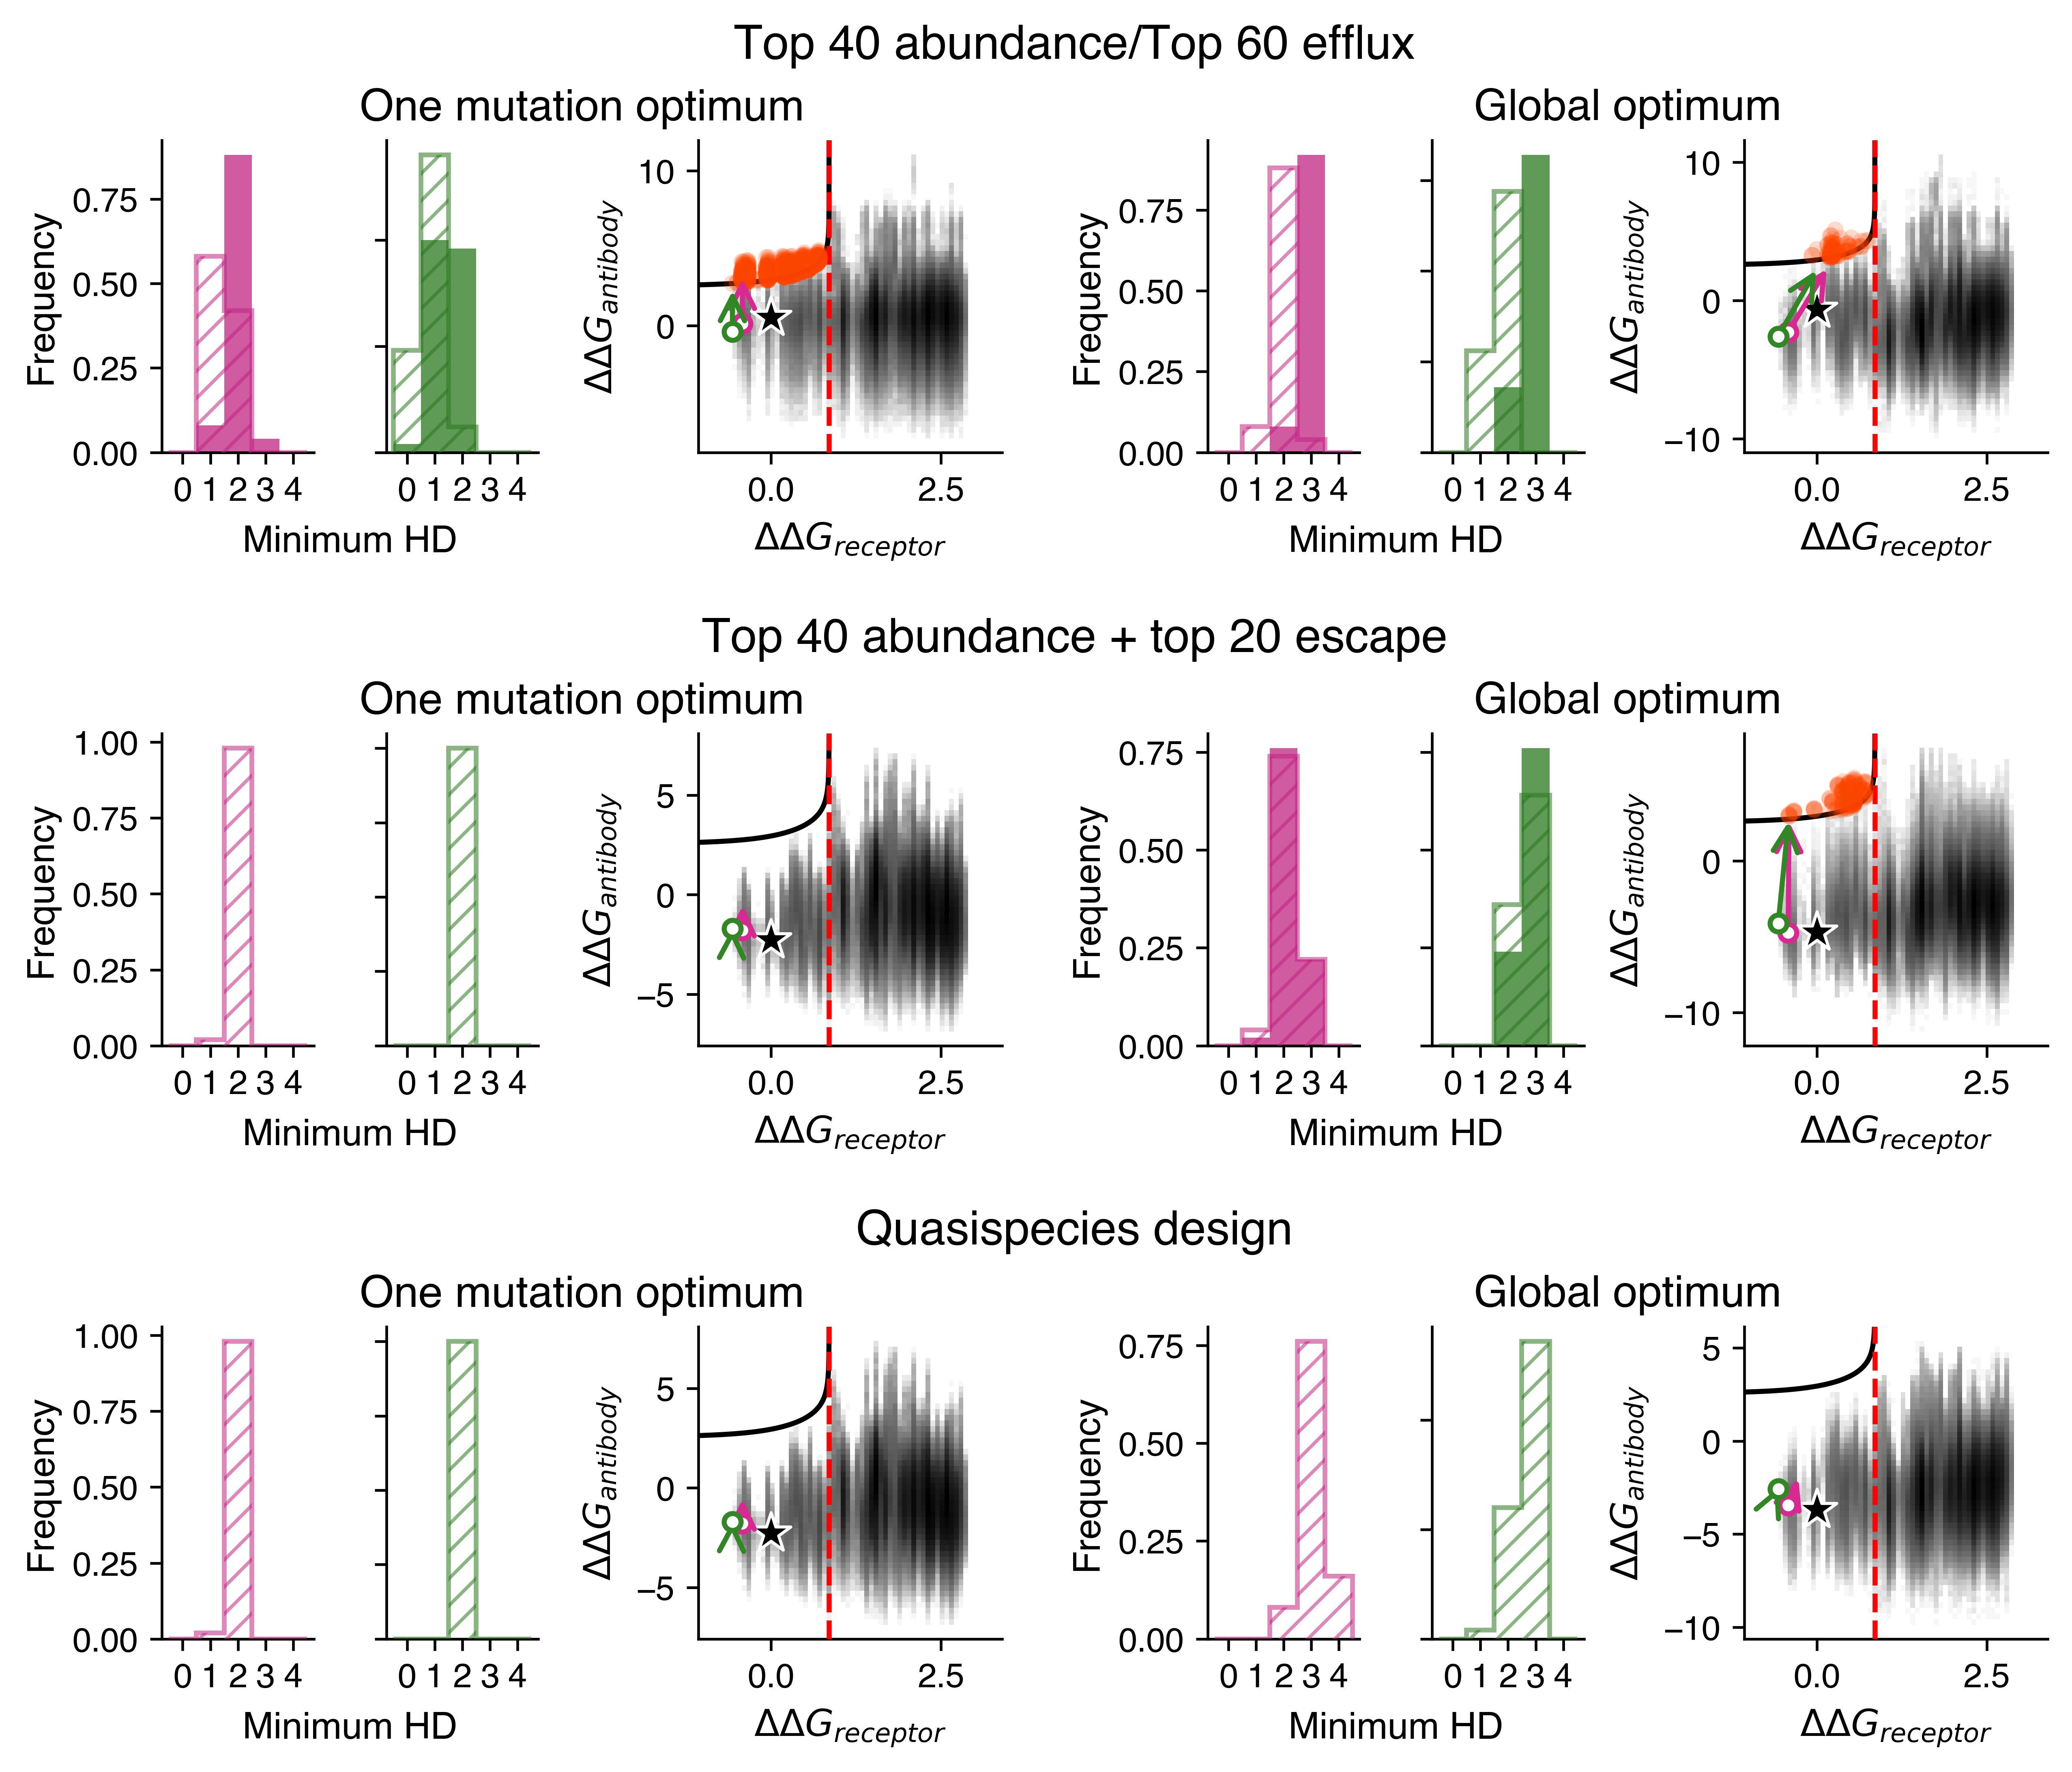

In [5]:
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(nrows=3, ncols=9, width_ratios=[1, 1, 0.1, 2, 0.4, 1, 1, 0.1, 2], hspace=0.9, wspace=0.5)

axes = [fig.add_subplot(gs[r, c]) for r in range(3) for c in [0,1,3,5,6,8]]

row_labels = ["Top 40 abundance/Top 60 efflux", "Top 40 abundance + top 20 escape", "Quasispecies design"]
for i in range(3):
    y = axes[i*6].get_position().y1
    fig.text(0.5, y + 0.037, row_labels[i], ha="center", va="bottom", fontsize=14, fontweight="bold")

for i in range(0, len(axes), 3):
    for ax in axes[i:i+2]:
        ax.set_xticks([0, 1, 2, 3, 4])
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1])

    axes[i].set_ylabel("Frequency")
    axes[i+1].set_yticklabels([])
    
    pos1 = axes[i].get_position()
    pos2 = axes[i + 1].get_position()

    x = (pos1.x1+pos2.x0)/2
    y = pos1.y0 - 0.055
    fig.text(x, y, f"Minimum HD", ha="center", va="bottom")

left_x = (axes[0].get_position().x0 + axes[2].get_position().x1) / 2
right_x = (axes[3].get_position().x0 + axes[5].get_position().x1) / 2

for i in range(3):
    y = axes[i * 6].get_position().y1 + 0.027
    fig.text(left_x, y, "One mutation optimum", ha="center", va="top", fontsize=13)
    fig.text(right_x, y, "Global optimum", ha="center", va="top", fontsize=13)

#Top 40 abundance/Top 60 efflux
#QFESR
base_dir = "../Simulation_data/QFESR_Ab/sim_outputs_biphasic"
QFESR_dataframe = pd.read_csv('../EvoEF_predictions/predictions_QFESR_Ab.csv', index_col=0)
totals_admin365 = pd.read_csv(base_dir+'/totals_time365_dose2p8e-06_seed1.csv')
topk_admin365 = pd.read_csv(base_dir+'/topk_time365_dose2p8e-06_seed1.csv')
totals_admin730 = pd.read_csv(base_dir+'/totals_time730_dose2p8e-06_seed1.csv')
topk_admin730 = pd.read_csv(base_dir+'/topk_time730_dose2p8e-06_seed1.csv')
escape_seqs_R0_1_QFESR = get_escape_seqs(QFESR_dataframe, params, 2.8e-6, ddg_threshold=1)
escape_seqs_R0_0p25_QFESR = get_escape_seqs(QFESR_dataframe, params, 2.8e-6, ddg_threshold=0.25)
plot_min_hamming_histogram_compare(axes[0], topk_admin365, 365, escape_seqs_R0_1_QFESR, escape_seqs_R0_0p25_QFESR, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[2], legend=False)
plot_min_hamming_histogram_compare(axes[1], topk_admin730, 730, escape_seqs_R0_1_QFESR, escape_seqs_R0_0p25_QFESR, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[4], legend=False)
plot_ddg_landscape(axes[2], QFESR_dataframe, params, 2.8e-6, show_colorbar=False, show_R0_no_Ab_contour=True, bins=50)
draw_population_trajectory(axes[2], topk_admin365, QFESR_dataframe, ab_time=365, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[2])
draw_population_trajectory(axes[2], topk_admin730, QFESR_dataframe, ab_time=730, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[4])

#QWEEF
base_dir = "../Simulation_data/QWEEF_Ab/sim_outputs_biphasic"
QWEEF_dataframe = pd.read_csv('../EvoEF_predictions/predictions_QWEEF_Ab.csv', index_col=0)
totals_admin365 = pd.read_csv(base_dir+'/totals_time365_dose2p8e-06_seed1.csv')
topk_admin365 = pd.read_csv(base_dir+'/topk_time365_dose2p8e-06_seed1.csv')
totals_admin730 = pd.read_csv(base_dir+'/totals_time730_dose2p8e-06_seed1.csv')
topk_admin730 = pd.read_csv(base_dir+'/topk_time730_dose2p8e-06_seed1.csv')
escape_seqs_R0_1_QWEEF = get_escape_seqs(QWEEF_dataframe, params, 2.8e-6, ddg_threshold=1)
escape_seqs_R0_0p25_QWEEF = get_escape_seqs(QWEEF_dataframe, params, 2.8e-6, ddg_threshold=0.25)
plot_min_hamming_histogram_compare(axes[3], topk_admin365, 365, escape_seqs_R0_1_QWEEF, escape_seqs_R0_0p25_QWEEF, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[2], legend=False)
plot_min_hamming_histogram_compare(axes[4], topk_admin730, 730, escape_seqs_R0_1_QWEEF, escape_seqs_R0_0p25_QWEEF, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[4], legend=False)
plot_ddg_landscape(axes[5], QWEEF_dataframe, params, 2.8e-6, show_colorbar=False, show_R0_no_Ab_contour=True, bins=50)
draw_population_trajectory(axes[5], topk_admin365, QWEEF_dataframe, ab_time=365, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[2])
draw_population_trajectory(axes[5], topk_admin730, QWEEF_dataframe, ab_time=730, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[4])

#Top 40 abundance + top 20 escape
#GFEKR
base_dir = "../Simulation_data/GFEKR_Ab/sim_outputs_biphasic"
GFEKR_dataframe = pd.read_csv('../EvoEF_predictions/predictions_GFEKR_Ab.csv', index_col=0)
totals_admin365 = pd.read_csv(base_dir+'/totals_time365_dose2p8e-06_seed1.csv')
topk_admin365 = pd.read_csv(base_dir+'/topk_time365_dose2p8e-06_seed1.csv')
totals_admin730 = pd.read_csv(base_dir+'/totals_time730_dose2p8e-06_seed1.csv')
topk_admin730 = pd.read_csv(base_dir+'/topk_time730_dose2p8e-06_seed1.csv')
escape_seqs_R0_1_GFEKR = get_escape_seqs(GFEKR_dataframe, params, 2.8e-6, ddg_threshold=1)
escape_seqs_R0_0p25_GFEKR = get_escape_seqs(GFEKR_dataframe, params, 2.8e-6, ddg_threshold=0.25)
plot_min_hamming_histogram_compare(axes[6], topk_admin365, 365, escape_seqs_R0_1_GFEKR, escape_seqs_R0_0p25_GFEKR, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[2], legend=False)
plot_min_hamming_histogram_compare(axes[7], topk_admin730, 730, escape_seqs_R0_1_GFEKR, escape_seqs_R0_0p25_GFEKR, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[4], legend=False)
plot_ddg_landscape(axes[8], GFEKR_dataframe, params, 2.8e-6, show_colorbar=False, show_R0_no_Ab_contour=True, bins=50)
draw_population_trajectory(axes[8], topk_admin365, GFEKR_dataframe, ab_time=365, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[2])
draw_population_trajectory(axes[8], topk_admin730, GFEKR_dataframe, ab_time=730, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[4])

#AWWKF
base_dir = "../Simulation_data/AWWKF_Ab/sim_outputs_biphasic"
AWWKF_dataframe = pd.read_csv('../EvoEF_predictions/predictions_AWWKF_Ab.csv', index_col=0)
totals_admin365 = pd.read_csv(base_dir+'/totals_time365_dose2p8e-06_seed1.csv')
topk_admin365 = pd.read_csv(base_dir+'/topk_time365_dose2p8e-06_seed1.csv')
totals_admin730 = pd.read_csv(base_dir+'/totals_time730_dose2p8e-06_seed1.csv')
topk_admin730 = pd.read_csv(base_dir+'/topk_time730_dose2p8e-06_seed1.csv')
escape_seqs_R0_1_AWWKF = get_escape_seqs(AWWKF_dataframe, params, 2.8e-6, ddg_threshold=1)
escape_seqs_R0_0p25_AWWKF = get_escape_seqs(AWWKF_dataframe, params, 2.8e-6, ddg_threshold=0.25)
plot_min_hamming_histogram_compare(axes[9], topk_admin365, 365, escape_seqs_R0_1_AWWKF, escape_seqs_R0_0p25_AWWKF, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[2], legend=False)
plot_min_hamming_histogram_compare(axes[10], topk_admin730, 730, escape_seqs_R0_1_AWWKF, escape_seqs_R0_0p25_AWWKF, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[4], legend=False)
plot_ddg_landscape(axes[11], AWWKF_dataframe, params, 2.8e-6, show_colorbar=False, show_R0_no_Ab_contour=True, bins=50)
draw_population_trajectory(axes[11], topk_admin365, AWWKF_dataframe, ab_time=365, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[2])
draw_population_trajectory(axes[11], topk_admin730, AWWKF_dataframe, ab_time=730, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[4])

#Quasispecies design
#GFEKR
base_dir = "../Simulation_data/GFEKR_Ab/sim_outputs_biphasic"
totals_admin365 = pd.read_csv(base_dir+'/totals_time365_dose2p8e-06_seed1.csv')
topk_admin365 = pd.read_csv(base_dir+'/topk_time365_dose2p8e-06_seed1.csv')
totals_admin730 = pd.read_csv(base_dir+'/totals_time730_dose2p8e-06_seed1.csv')
topk_admin730 = pd.read_csv(base_dir+'/topk_time730_dose2p8e-06_seed1.csv')
plot_min_hamming_histogram_compare(axes[12], topk_admin365, 365, escape_seqs_R0_1_GFEKR, escape_seqs_R0_0p25_GFEKR, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[2], legend=False)
plot_min_hamming_histogram_compare(axes[13], topk_admin730, 730, escape_seqs_R0_1_GFEKR, escape_seqs_R0_0p25_GFEKR, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[4], legend=False)
plot_ddg_landscape(axes[14], GFEKR_dataframe, params, 2.8e-6, show_colorbar=False, show_R0_no_Ab_contour=True, bins=50)
draw_population_trajectory(axes[14], topk_admin365, GFEKR_dataframe, ab_time=365, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[2])
draw_population_trajectory(axes[14], topk_admin730, GFEKR_dataframe, ab_time=730, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[4])

#MWEQK
base_dir = "../Simulation_data/MWEQK_Ab/sim_outputs_biphasic"
MWEQK_dataframe = pd.read_csv('../EvoEF_predictions/predictions_MWEQK_Ab.csv', index_col=0)
totals_admin365 = pd.read_csv(base_dir+'/totals_time365_dose2p8e-06_seed1.csv')
topk_admin365 = pd.read_csv(base_dir+'/topk_time365_dose2p8e-06_seed1.csv')
totals_admin730 = pd.read_csv(base_dir+'/totals_time730_dose2p8e-06_seed1.csv')
topk_admin730 = pd.read_csv(base_dir+'/topk_time730_dose2p8e-06_seed1.csv')
escape_seqs_R0_1_MWEQK = get_escape_seqs(MWEQK_dataframe, params, 2.8e-6, ddg_threshold=1)
escape_seqs_R0_0p25_MWEQK = get_escape_seqs(MWEQK_dataframe, params, 2.8e-6, ddg_threshold=0.25)
plot_min_hamming_histogram_compare(axes[15], topk_admin365, 365, escape_seqs_R0_1_MWEQK, escape_seqs_R0_0p25_MWEQK, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[2], legend=False)
plot_min_hamming_histogram_compare(axes[16], topk_admin730, 730, escape_seqs_R0_1_MWEQK, escape_seqs_R0_0p25_MWEQK, top_k_pre=50, color=sns.husl_palette(5, h=0.55, l=0.45)[4], legend=False)
plot_ddg_landscape(axes[17], MWEQK_dataframe, params, 2.8e-6, show_colorbar=False, show_R0_no_Ab_contour=True, bins=50)
draw_population_trajectory(axes[17], topk_admin365, MWEQK_dataframe, ab_time=365, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[2])
draw_population_trajectory(axes[17], topk_admin730, MWEQK_dataframe, ab_time=730, pre_offset=-1, post_offset=50, color=sns.husl_palette(5, h=0.55, l=0.5)[4])

plt.savefig('FigS6.png', dpi=600, bbox_inches='tight')

## Generate Fig. S7: Compare saturating and exponential receptor-binding affinity and infection rate relationships

In [6]:
def _integrated_V(topk_df):
    grp = topk_df.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grp.pivot_table(index="sequence", columns="time", values="V", aggfunc="sum", fill_value=0.0)
    times = np.sort(pivot.columns.astype(float))
    pivot = pivot.reindex(columns=times, fill_value=0.0)
    areas = np.trapezoid(pivot.to_numpy(float), x=times, axis=1)
    return dict(zip(pivot.index, areas))

def compute_global_topk(topk_dfs, top_k=20):
    """Compute the global top-K sequences across runs by summing integrated viral loads per variant."""
    
    totals = {}
    for df in topk_dfs:
        for seq, area in _integrated_V(df).items():
            totals[seq] = totals.get(seq, 0.0) + area
    return [s for s, _ in sorted(totals.items(), key=lambda x: x[1], reverse=True)[:top_k]]

def build_color_map(global_seqs, wt_seq='DIRQH', wt_slot=0, palette="tab20"):
    """Build a sequence -> color mapping for a set of viral sequences.
    Give the wild type a specific color in the palette."""
    tab20 = sns.color_palette(palette, 20)
    wt_rgb = to_rgb(tab20[wt_slot % 20])
    pool = [to_rgb(c) for i, c in enumerate(tab20) if i != wt_slot % 20]

    cmap: dict = {}
    if wt_seq in global_seqs:
        cmap[wt_seq] = wt_rgb

    pi = 0
    for s in global_seqs:
        if s not in cmap:
            cmap[s] = pool[pi % len(pool)]
            pi += 1

    cmap["__others__"] = "#ebebebf2"
    return cmap

def _build_pivot(topk_df, times):
    grp = topk_df.groupby(["sequence", "time"], as_index=False)["V"].sum()
    pivot = grp.pivot_table(index="sequence", columns="time", values="V", aggfunc="sum", fill_value=0.0)
    return pivot.reindex(columns=times, fill_value=0.0)

def _freq_matrix(pivot, sequences, totals_ts):
    rows = [pivot.loc[s].to_numpy(float) if s in pivot.index else np.zeros(pivot.shape[1]) for s in sequences]
    arr = np.vstack(rows) if rows else np.zeros((1, pivot.shape[1]))

    with np.errstate(divide="ignore", invalid="ignore"):
        freqs = np.divide(arr, totals_ts[np.newaxis, :], where=totals_ts > 0)
        freqs[:, totals_ts == 0] = 0.0

    others = np.clip(1.0 - freqs.sum(axis=0), 0.0, 1.0)
    return np.vstack([freqs, others])

def _shade_below_vl(ax, times, totals_ts, threshold=1, color="#4a4a4a", y_top=1.0, y_bottom=-1.0):
    low = totals_ts < threshold
    if not low.any():
        return
    pad = np.r_[0, low.view(np.int8), 0]
    diffs = np.diff(pad)
    for s_idx, e_idx in zip(np.where(diffs == 1)[0], np.where(diffs == -1)[0]):
        t_seg = times[s_idx - 1: e_idx]
        if t_seg.size:
            ax.fill_between(t_seg, y_bottom, y_top, color=color, alpha=1.0,
                            linewidth=0, zorder=10)

def stacked_frequency_plot(ax, totals_df, topk_df, sequences, color_map, classification=None,
                            x_max=365, wt_seq='DIRQH', vl_mode=False, wt_legend=False, y_floor=-1):
    """Plot the frequencies of the top-K variants over time in a simulation.
    Optionally takes in a variant classification for labeling core/accessory/unique variants from multiple simulations.
    If vl_mode=TRUE, the VL curve is plotted and abundances on a log scale are shown underneath this curve."""
    times = np.sort(totals_df["time"].unique())
    totals_ts = totals_df.set_index("time").reindex(times)["sum_V"].fillna(0.0).to_numpy(float)
    n_seqs = len(sequences)
    pivot = _build_pivot(topk_df, times)
    freq_mat = _freq_matrix(pivot, sequences, totals_ts)

    if vl_mode:
        log_vl = np.where(totals_ts > 0, np.log10(totals_ts / 5000), np.nan)
        above_threshold = totals_ts >= 0.01
        log_vl_clipped = np.where(above_threshold, log_vl, np.nan)
        span = log_vl_clipped - y_floor
        weights = np.where(span > 0, span, np.nan)
        y_max = np.log10(3e5)
    else:
        weights = np.ones(len(times))
        y_max = 1.0

    stack = freq_mat * weights[np.newaxis, :]
    cum = np.nancumsum(stack, axis=0) if vl_mode else np.cumsum(stack, axis=0)
    base = y_floor if vl_mode else 0.0
    bottoms = np.vstack([np.full(len(times), base), base + cum[:-1]])

    def _bot_top(i):
        return bottoms[i], bottoms[i] + stack[i]

    labels = sequences + ["__others__"]
    for i, lbl in enumerate(labels):
        color = color_map.get(lbl, color_map["__others__"])
        bot_i, top_i = _bot_top(i)
        ax.fill_between(times, bot_i, top_i, facecolor=color, linewidth=0)
        #Hatching for accessory/unique sequences
        if i < n_seqs and classification and lbl in classification:
            cat = classification[lbl]
            hatch = ("////" if cat == "accessory" else "xxxx" if cat == "unique" else None)
            if hatch:
                ax.fill_between(times, bot_i, top_i, facecolor="none", edgecolor="white", linewidth=0, hatch=hatch, alpha=0.5)

    _shade_below_vl(ax, times, totals_ts, y_top=y_max)
    ax.set_xlim(times.min(), x_max)

    if vl_mode:
        ax.plot(times, log_vl, color="black", lw=1.5, zorder=8)
        y_ceil = int(np.ceil(y_max))
        ticks = list(range(y_floor, y_ceil + 1))
        ax.set_yticks(ticks)
        ax.set_yticklabels([f"$10^{{{t}}}$" for t in ticks])
        ax.set_ylim(y_floor, y_max)
        ax.set_ylabel("Viral Load (mL$^{-1}$)")
    else:
        ax.set_ylim(0, 1)
        ax.set_ylabel("Frequency")

    if wt_legend and wt_seq in sequences:
        ax.legend(handles=[mpatches.Patch(color=color_map[wt_seq], label=f"Wild type ({wt_seq})")], bbox_to_anchor=(0.5, 1.18), loc="upper center", frameon=False)

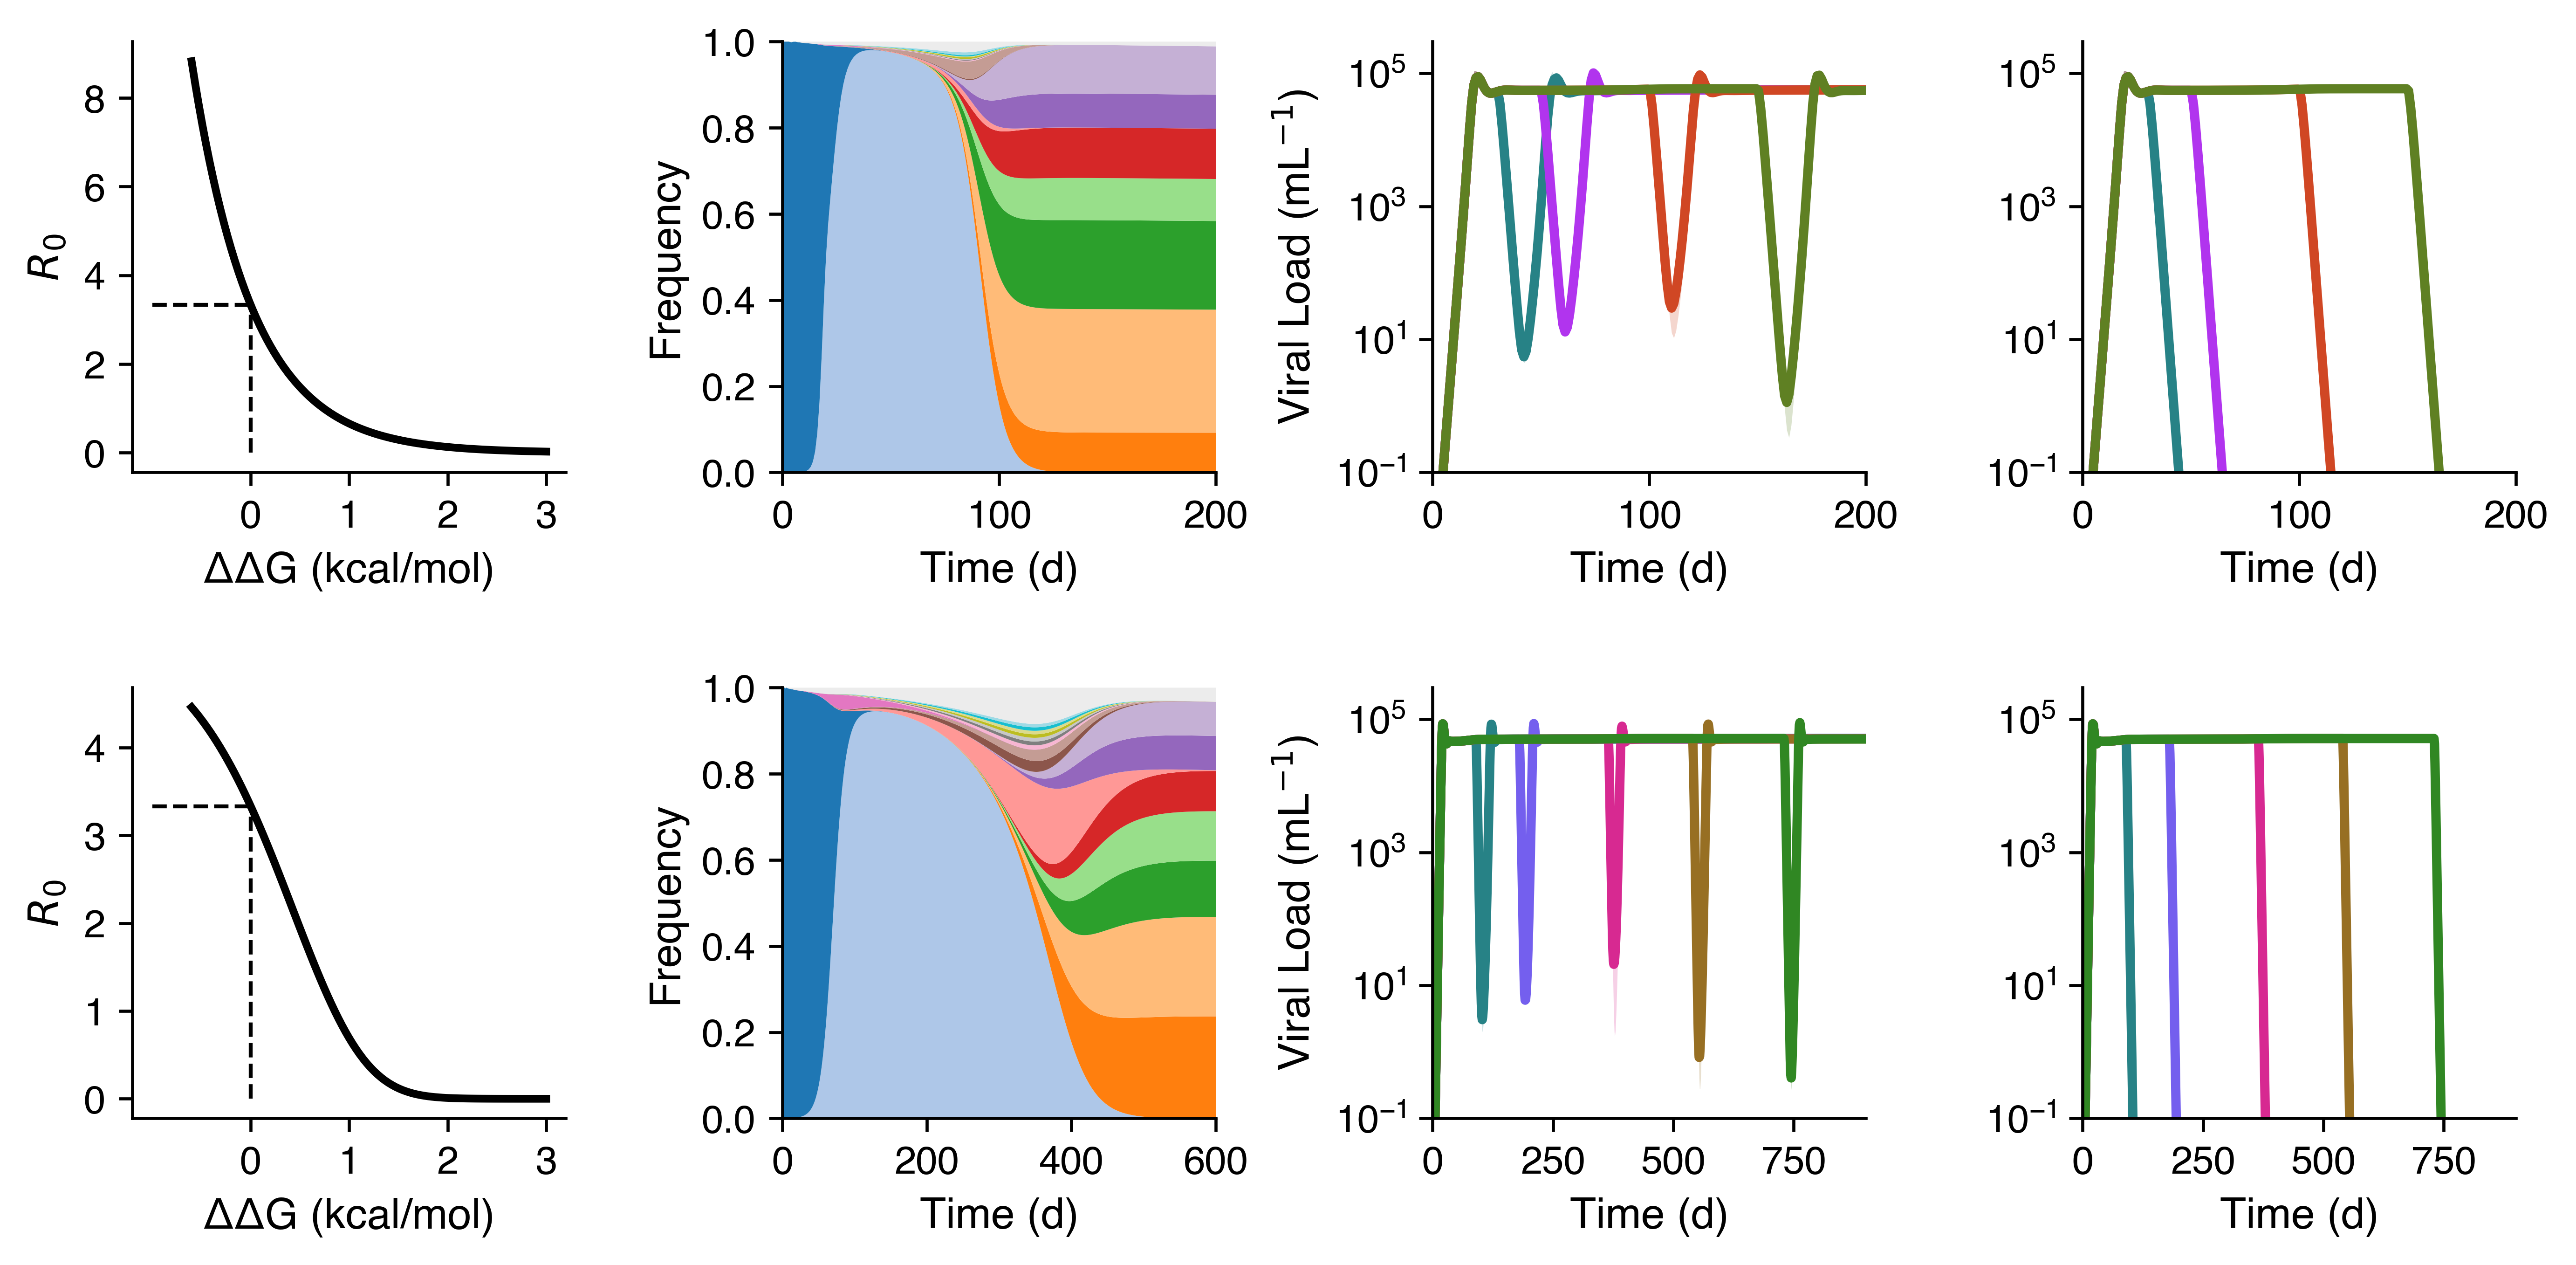

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5), constrained_layout=False)
axes = axes.flatten()
fig.subplots_adjust(wspace=0.5, hspace=0.5)

#R0 as a function of ddG
def r0_fun_exp(ddg_receptor, ddg_ab, Ab_dose, p):
    ddg_receptor = np.asarray(ddg_receptor, dtype=float)
    ddg_ab = np.asarray(ddg_ab, dtype=float)
    Ab_dose = np.asarray(Ab_dose, dtype=float)
    return (p['beta_wt']*np.exp(-ddg_receptor / p['RT'])*p['lambda_T']*p['gamma']*p['n'])/(p['c']*p['d']*(p['delta1']+p['gamma'])*(1+((Ab_dose/p['KD_WT'])*np.exp(-ddg_ab/p['RT']))))

ddg_range = np.linspace(-0.6, 3, 100)
axes[0].plot(ddg_range, r0_fun_exp(ddg_range, 0, 0, params), color='k', lw=2)
axes[0].set_xticks([0, 1, 2, 3])
axes[0].set_xlabel("ΔΔG (kcal/mol)")
axes[0].set_ylabel(f"$R_0$")
axes[0].hlines(3.33333, xmin=-1, xmax=0, color='k', linestyle='--', lw=1)
axes[0].vlines(0, ymin=0, ymax=3.3333, color='k', linestyle='--', lw=1)

axes[4].plot(ddg_range, r0_fun(ddg_range, 0, 0, params), color='k', lw=2)
axes[4].set_xticks([0, 1, 2, 3])
axes[4].set_xlabel("ΔΔG (kcal/mol)")
axes[4].set_ylabel(f"$R_0$")
axes[4].hlines(3.33333, xmin=-1, xmax=0, color='k', linestyle='--', lw=1)
axes[4].vlines(0, ymin=0, ymax=3.3333, color='k', linestyle='--', lw=1)

#Frequency plots (no Ab)
base_dir = "../Simulation_data/No_Ab/sim_outputs"
totals_sigmoid = pd.read_csv(base_dir+'/totals_noAb_seed8.csv')
topk_sigmoid = pd.read_csv(base_dir+'/topk_noAb_seed8.csv')
topk_seqs_sigmoid = compute_global_topk([topk_sigmoid])
colmap_sigmoid = build_color_map(topk_seqs_sigmoid)
stacked_frequency_plot(axes[5], totals_sigmoid, topk_sigmoid, topk_seqs_sigmoid, colmap_sigmoid, x_max=600)
axes[5].set_xlabel("Time (d)")

base_dir = "../Simulation_data/No_Ab/sim_outputs_exponential"
totals_exp = pd.read_csv(base_dir+'/totals_noAb_seed8.csv')
topk_exp = pd.read_csv(base_dir+'/topk_noAb_seed8.csv')
stacked_frequency_plot(axes[1], totals_exp, topk_exp, topk_seqs_sigmoid, colmap_sigmoid, x_max=200)
axes[1].set_xlabel("Time (d)")

#WT Ab
plot_viral_load_panel(axes[2], 2.8e-6, 'biphasic', base_dir='../Simulation_data/WT_Ab/Exponential', timepoints=(30, 50, 100, 150), seeds=(1,2,3), xlimits=(0, 200))
plot_viral_load_panel(axes[6], 2.8e-6, 'biphasic')
axes[6].set_xticks([0, 250, 500, 750])

#Designed Ab
plot_viral_load_panel(axes[3], 2.8e-6, 'biphasic', base_dir='../Simulation_data/GFEKR_Ab/Exponential', timepoints=(30, 50, 100, 150), seeds=(1,2,3), xlimits=(0, 200))
axes[3].set_ylabel("")
plot_viral_load_panel(axes[7], 2.8e-6, 'biphasic', base_dir='../Simulation_data/GFEKR_Ab')
axes[7].set_ylabel("")
axes[7].set_xticks([0, 250, 500, 750])

plt.savefig("FigS7.png", dpi=600, bbox_inches='tight')